# Spectral Clustering
### TMA4205 Numerical Linear Algebra

In [2]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.linalg as la
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans

In [3]:
# Hand-out code
point_size = 10
plt.ion()

def make_data(n=100, sigma = 0.5, pl=False):
    '''
    Make four clusters: noisy data points around 4 centres.
    
    Parameters:
    n: number of points in each cluster (default 100)
    sigma: Level of noise (default 0.5)
    pl: Make a plot or not  (default False)

    Return:
    X: the data points, np.array of shape (4*n,2)
    '''
    centers = np.array([[0, 0],[1, 5],[4, 0],[5, 5]])
    X = np.vstack([center + sigma * np.random.randn(n, 2) for center in centers])
    if pl:
        plt.clf()
        plt.scatter(X[:, 0], X[:, 1], s=point_size)
        plt.axis('equal')
    return X


def make_moons(n = 150, sigma = 0.12, pl = False):
    '''
    Make four interleaving half circles.

    Parameters:
    n: Number of data points in each half circle (default 150)
    sigma : Noise level, or the spread of data (default 0.12)
    pl:  Make a plot or not  (default False)

    Return:
    X: The data points, np.array of shape (4*n,2)
    '''
    X = []
    labels = []
    # Four moons, separated spatially
    centers = [(0, 0), (1, 0), (-2.5, -2), (-1, -2)]
    for j, (cx, cy) in enumerate(centers):
        t = np.linspace(0, np.pi, n)
        x = 1.5 * np.cos(t)
        y = 1.5 * np.sin(t)
        # Put the four moons in different orientations
        if j == 1:
            y = -y
        elif j == 2:
            x = -x
        elif j == 3:
            x = -x
            y = -y
        x += cx + 0.12*np.random.randn(n)
        y += cy + 0.12*np.random.randn(n)
        X.append(np.column_stack((x, y)))
        labels.extend([j]*n)
    X = np.vstack(X)
    labels = np.array(labels)

    if pl:
        plt.clf()
        plt.scatter(X[:,0], X[:,1], c=labels, s=point_size)
        plt.axis("equal")
        plt.show()
    return X

### Part 1: Understanding spectral clustering

In this task we construct a symmetric $k$-nearest-neighbour graph and assign weights to its edges using the Gaussian similarity function
$$
s(x_i, x_j) = exp \left( \frac{- ||x_i - x_j||_2^2}{2 \sigma^2} \right)
$$
where $\sigma$ controls the width of the neighbourhood.

The unnormalized graph Laplacian matrix is defined as 
$$ L = D - W$$
**Proposition 1 (Properties of $L$).** *The matrix $L$ satisfies the following properties:*

1. *For every vector $f \in \mathbb{R}^n$ we have*
$$
f' L f = \frac{1}{2} \sum_{i,j=1}^{n} w_{ij} (f_i - f_j)^2.
$$
2. *$L$ is symmetric and positive semi-definite.*
3. *The smallest eigenvalue of $L$ is $0$, the corresponding eigenvector is the constant one vector $\mathbb{1}$.*
4. *$L$ has $n$ non-negative, real-valued eigenvalues $0 = \lambda_1 \leq \lambda_2 \leq \dots \leq \lambda_n$.*

In [34]:
def spectral_clustering(X, k=10, K=4, sigma=1):
    '''
    Spectral clustering algorithm.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        K: The number of clusters to find (default 4)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        C: The cluster labels, np.array of shape (N,)
    '''

    # Make the k-nearest neighbor graph
    S = kneighbors_graph(X, k, mode='distance', include_self=False)
    S = S.maximum(S.T).tocsr()

    # Compute the Gaussian weights on the existing edges only (keeps W sparse)
    W = S.copy()
    W.data = np.exp(-W.data**2 / (2 * sigma**2))

    # Compute the degree matrix D and the Laplacian L
    N = W.shape[0]
    D = np.zeros(N)
    for i in range(N):
        D[i] = np.sum(W[i, :])
    D = sp.diags(D)     # d = sp.diags(np.asarray(W.sum(axis=1)).ravel()) cheaper version
    L = (D - W).tocsr()

    # Compute the eigenvalues and eigenvectors of the Laplacian
    lambdas, V = la.eigh(L.toarray())
    U = V[:, :K]

    # Perform k-means clustering on the rows of U
    C = KMeans(K).fit(U).labels_

    return C


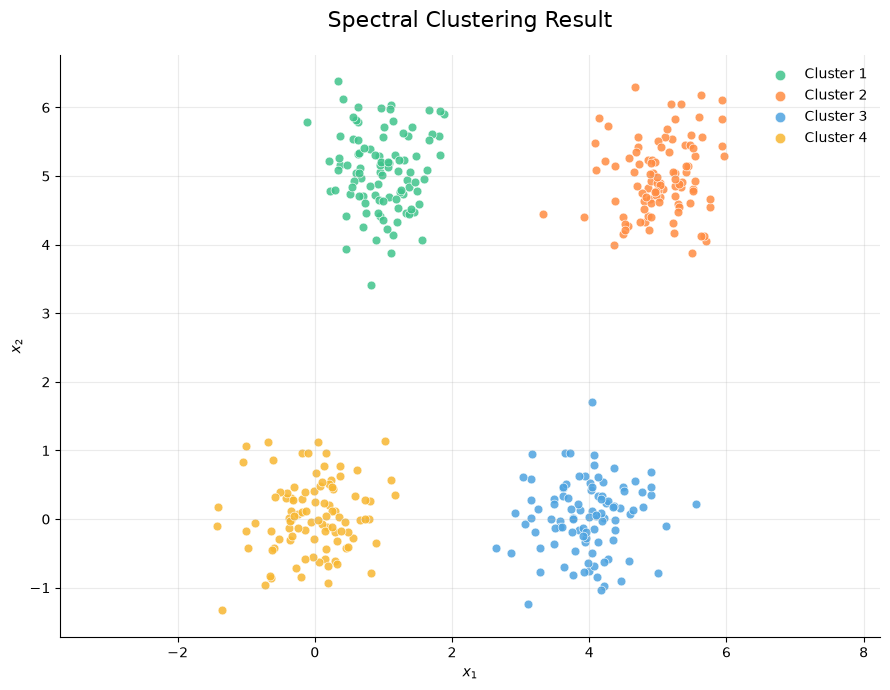

In [ ]:
colors = ["#3FC38B", "#FF8C42", "#4DA3E0", "#F7B731","#F26B6B",
              "#9B6BD6",  "#E85D9E", "#1B5E3F",]

X = make_data()  
C = spectral_clustering(X, k=10, K=4, sigma=1)


fig, ax = plt.subplots(figsize=(9, 7))

palette = np.array(colors)

for c in np.unique(C):
    mask = C == c
    ax.scatter(
        X[mask, 0], X[mask, 1],
        s=40,                      # larger markers
        color=palette[c],
        alpha=0.85,
        edgecolor="white",         # thin white outline separates overlapping points
        linewidth=0.5,
        label=f"Cluster {c + 1}",
    )

ax.set_title("Spectral Clustering Result", fontsize=16, pad=20)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal", adjustable="datalim")   # keeps the geometry undistorted
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="best", markerscale=1.2)

fig.tight_layout()
plt.show()

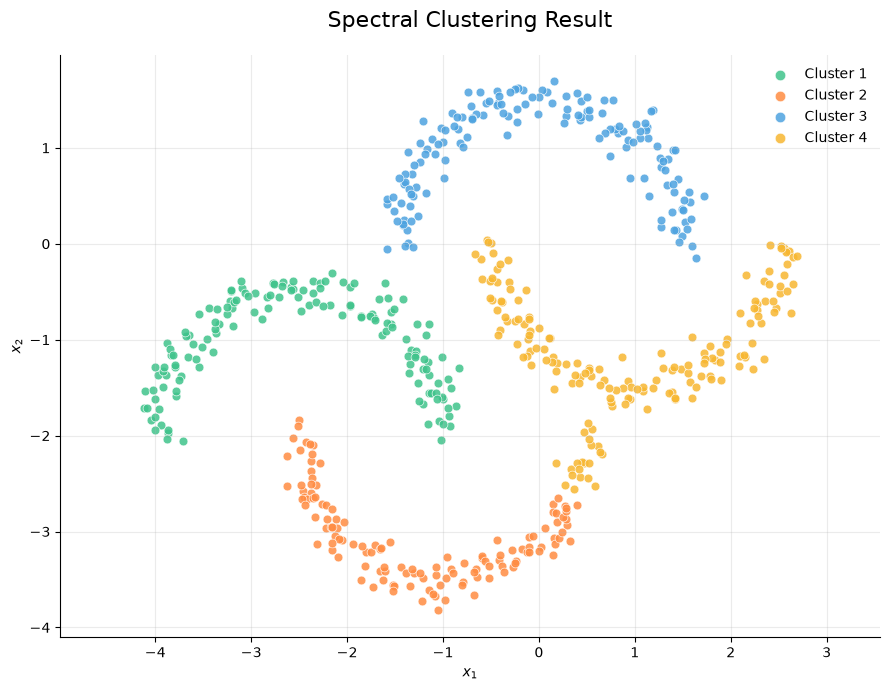

In [59]:
Y = make_moons()  
C = spectral_clustering(Y, k=10, K=4, sigma=1)


fig, ax = plt.subplots(figsize=(9, 7))

palette = np.array(colors)

for c in np.unique(C):
    mask = C == c
    ax.scatter(
        Y[mask, 0], Y[mask, 1],
        s=40,                      # larger markers
        color=palette[c],
        alpha=0.85,
        edgecolor="white",         # thin white outline separates overlapping points
        linewidth=0.5,
        label=f"Cluster {c + 1}",
    )

ax.set_title("Spectral Clustering Result", fontsize=16, pad=20)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal", adjustable="datalim")   # keeps the geometry undistorted
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="best", markerscale=1.2)

fig.tight_layout()
plt.show()